**Freight Rate Prediction_EDA**

**1. Loading the datasets**

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

train_data = pd.read_csv("/content/train-test.csv")
valid_data = pd.read_csv("/content/validation.csv")
december_data = pd.read_csv("/content/december-chart-inputs.csv")

for name, dataset in [
    ("Training", train_data),
    ("Validation", valid_data),
    ("December", december_data)
]:
    print(f"{name} dataset: {dataset.shape}")


Training dataset: (48000, 14)
Validation dataset: (12000, 13)
December dataset: (31, 7)


**2. Dataset Schema and Feature Availability**

This step compares the columns to identify the variables missing from the December scenario.

In [3]:

print("Training features:", train_data.columns.tolist())
print("Validation features:", valid_data.columns.tolist())
print("December features:", december_data.columns.tolist())

# Identify fields unavailable for December predictions
december_missing = train_data.columns.difference(december_data.columns)
print("\nFields unavailable in December:")
print(december_missing.tolist())


Training features: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
Validation features: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
December features: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']

Fields unavailable in December:
['delivery_lat', 'delivery_lon', 'load_id', 'market_index', 'pickup_lat', 'pickup_lon', 'posted_rate', 'quote_signal']


**3. Data Quality and Missing Observations**

In [4]:

print("=== Training dataset summary ===")
print(train_data.info())

for label, data in [("Training", train_data), ("Validation", valid_data)]:
    print(f"\n=== Missing values: {label} ===")
    print(data.isna().sum()[lambda x: x > 0])


=== Training dataset summary ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB
None

=== Missing values: Training ===
weight          300
market_index    374
dtype: int64

=== Missing values: Valid

**4. Relationship Between Distance and Freight Rate**

We examine the effect of distance on the fare, and then we visualize their relationship.

posted_rate     1.000000
distance        0.908519
weight          0.034840
market_index    0.034165
quote_signal   -0.039858
pickup_lat     -0.090873
delivery_lat   -0.091970
pickup_lon     -0.255058
delivery_lon   -0.257086
Name: posted_rate, dtype: float64


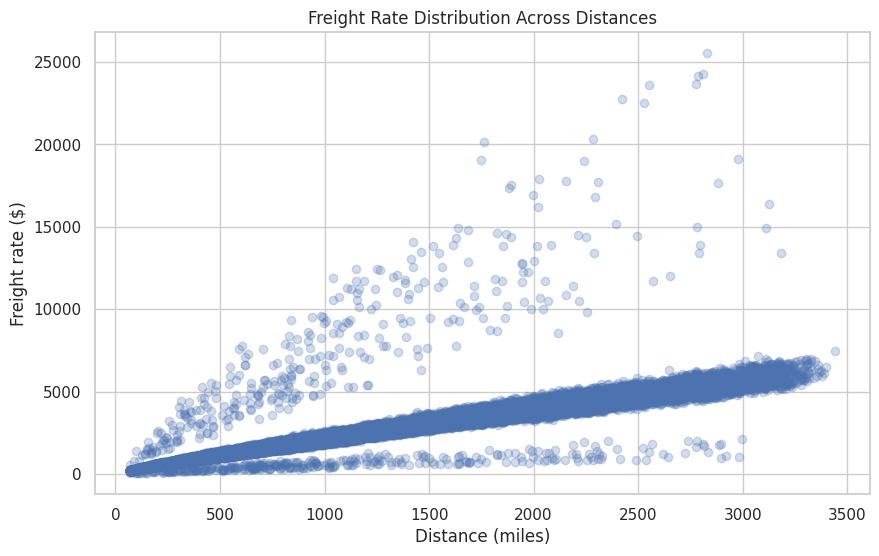

In [5]:

num_data = train_data.select_dtypes(include="number")
print(num_data.corr()["posted_rate"].sort_values(ascending=False))

plt.scatter(train_data["distance"], train_data["posted_rate"], alpha=0.25)
plt.xlabel("Distance (miles)")
plt.ylabel("Freight rate ($)")
plt.title("Freight Rate Distribution Across Distances")
plt.show()


**5. Weekly Market Index Patterns**

We are now examining how the market_index varies by day of the week.

weekday
0    0.999586
1    1.075435
2    1.153226
3    1.178978
4    1.134310
5    1.047481
6    0.988633
Name: market_index, dtype: float64


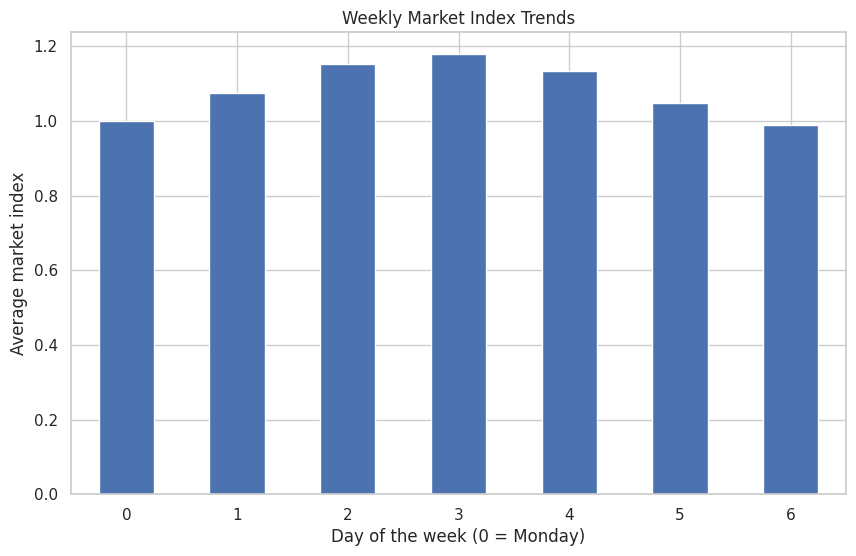

In [6]:

train_data["date"] = pd.to_datetime(train_data["date"])
train_data["weekday"] = train_data["date"].dt.dayofweek

market_weekly = train_data.groupby("weekday")["market_index"].mean()

print(market_weekly)

market_weekly.plot(kind="bar", rot=0)
plt.xlabel("Day of the week (0 = Monday)")
plt.ylabel("Average market index")
plt.title("Weekly Market Index Trends")
plt.show()


**6. Investigating the Quote Signal**

We compare the rate per mile with quote_signal for each month to see if their relationship changes over time.

In [7]:

train_data["month"] = train_data["date"].dt.month
train_data["rate_per_mile"] = (
    train_data["posted_rate"] / train_data["distance"].replace(0, np.nan)
)

for month, group in train_data.groupby("month"):
    corr = group["rate_per_mile"].corr(group["quote_signal"])
    print(f"Month {month:02d} | Correlation: {corr:.3f}")


Month 01 | Correlation: 0.447
Month 02 | Correlation: 0.479
Month 03 | Correlation: 0.486
Month 04 | Correlation: -0.472
Month 05 | Correlation: -0.459
Month 06 | Correlation: 0.477
Month 07 | Correlation: -0.468
Month 08 | Correlation: -0.014
Month 09 | Correlation: 0.481
Month 10 | Correlation: -0.434


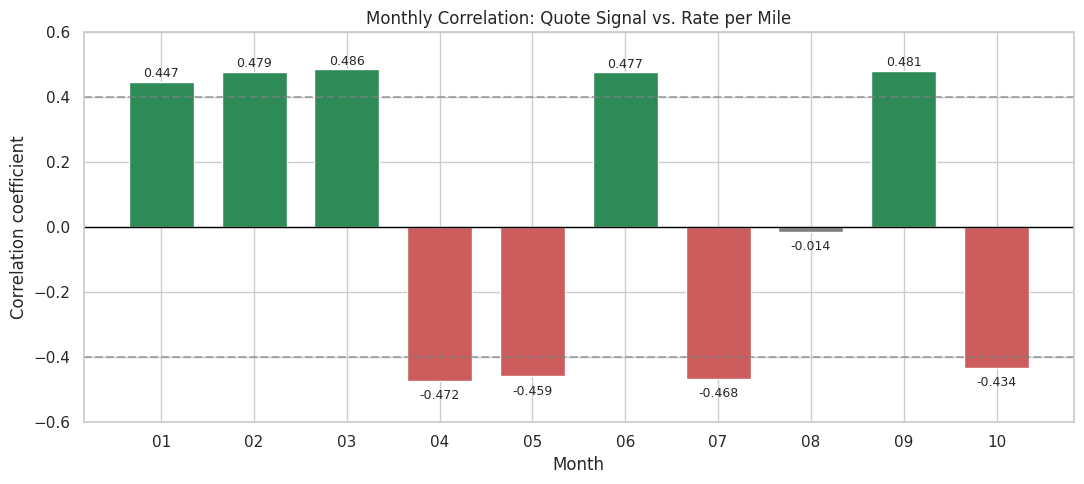

In [12]:

import numpy as np
import matplotlib.pyplot as plt

months = np.arange(1, 11)
correlations = [0.447, 0.479, 0.486, -0.472, -0.459,
                0.477, -0.468, -0.014, 0.481, -0.434]

colors = [
    "seagreen" if r > 0.1 else
    "indianred" if r < -0.1 else "gray"
    for r in correlations
]

plt.figure(figsize=(11, 5))
bars = plt.bar(months, correlations, color=colors, width=0.7)

plt.axhline(0, color="black", linewidth=1)
plt.axhline(0.4, color="gray", linestyle="--", alpha=0.6)
plt.axhline(-0.4, color="gray", linestyle="--", alpha=0.6)

for bar, value in zip(bars, correlations):
    offset = 0.025 if value >= 0 else -0.045
    plt.text(bar.get_x() + bar.get_width()/2,
             value + offset, f"{value:.3f}",
             ha="center", va="center", fontsize=9)

plt.xticks(months, [f"{m:02d}" for m in months])
plt.ylim(-0.6, 0.6)
plt.xlabel("Month")
plt.ylabel("Correlation coefficient")
plt.title("Monthly Correlation: Quote Signal vs. Rate per Mile")
plt.tight_layout()
plt.show()


**Interpretation of the Quote Signal Anomaly**

The monthly correlation analysis reveals an inconsistent relationship between quote_signal and rate_per_mile.
- Months 1, 2, 3, 6 and 9 — Positive correlation: Correlation coefficients range from 0.447 to 0.486, indicating that higher quote_signal values tend to be associated with higher freight rates per mile.
- Months 4, 5, 7 and 10 — Negative correlation: Coefficients range from −0.434 to −0.472, suggesting that higher quote_signal values tend to be associated with lower freight rates per mile.
- Month 8 — Almost no linear correlation: The coefficient is −0.014, indicating virtually no linear relationship between the two variables.

**Modeling Decision:** We will exclude quote_signal because its relationship with freight rates fluctuates across months and it is unavailable in the December dataset. This decision will be validated using a time-based model comparison.

**7. Freight Rates by Equipment Category**

We compare the distribution of the per-mile rate across the different vehicle categories.

This comparison helps determine whether the type of equipment provides useful information for predicting rates.

             count   mean    std    min    25%    50%    75%     max
equipment                                                           
Dry Van    27202.0  2.115  0.538  0.334  1.921  2.046  2.211  12.817
Flatbed     8753.0  2.295  0.610  0.354  2.076  2.220  2.407  12.950
Reefer     12045.0  2.383  0.615  0.386  2.168  2.312  2.495  14.125


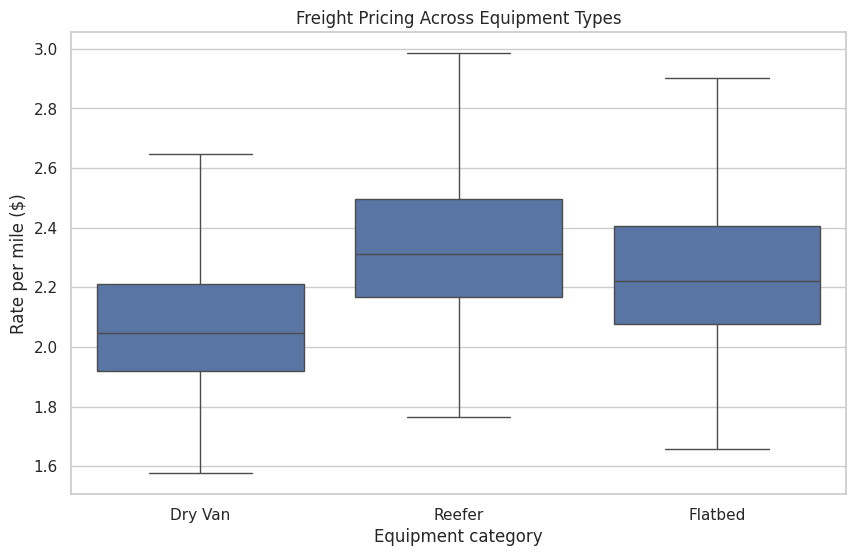

In [13]:

equipment_rates = train_data.groupby("equipment")["rate_per_mile"]
print(equipment_rates.describe().round(3))

sns.boxplot(data=train_data, x="equipment", y="rate_per_mile", showfliers=False)
plt.xlabel("Equipment category")
plt.ylabel("Rate per mile ($)")
plt.title("Freight Pricing Across Equipment Types")
plt.show()


8. Checking Coordinates for the December **Route**

In [14]:

pickup_coords = train_data.loc[
    train_data["pickup"].eq("Lexington"),
    ["pickup_lat", "pickup_lon"]
].drop_duplicates()

delivery_coords = train_data.loc[
    train_data["delivery"].eq("Fort Wayne"),
    ["delivery_lat", "delivery_lon"]
].drop_duplicates()

print("Lexington coordinates:\n", pickup_coords)
print("\nFort Wayne coordinates:\n", delivery_coords)

print("\nUnique pickup location:", len(pickup_coords) == 1)
print("Unique delivery location:", len(delivery_coords) == 1)


Lexington coordinates:
     pickup_lat  pickup_lon
28    36.99152   -84.99876

Fort Wayne coordinates:
     delivery_lat  delivery_lon
24      41.31561     -85.36206

Unique pickup location: True
Unique delivery location: True


**9. Time-Based Validation Strategy**

In [15]:

train_data["month"] = train_data["date"].dt.month

historical_data = train_data[train_data["date"] < "2025-10-01"]
future_holdout = train_data[
    (train_data["date"] >= "2025-10-01") &
    (train_data["date"] < "2025-11-01")
]

print("Historical training rows:", len(historical_data))
print("October validation rows:", len(future_holdout))


Historical training rows: 43147
October validation rows: 4853


**10. Conclusions :**

Based on the EDA findings, the following modeling choices are proposed:

- **Exclude quote_signal:** Its correlation with rate_per_mile varies across months, and it is unavailable in the December dataset.
- **Use Date Features:** Extract dayofweek, month, and day to capture potential temporal patterns.
- **Handle Missing Values:** Apply an appropriate imputation strategy to missing values in weight and market_index.
- **Include Equipment Type:** Retain equipment because the analysis shows differences in rate-per-mile distributions across categories.
- **Choose a Tree-Based Model:** Evaluate **HistGradientBoostingRegressor** using a time-based validation split to assess its ability to capture nonlinear relationships and predict future rates.